# Лабораторная работа 5. Кластерный анализ
**Вариант 3.** Задания 1-4 (k-means и иерархическая кластеризация): центры кластеров (-3; 1), (1; 1), (2; -3), seed = 3. Задание 5 (сеть Кохонена): K = 6, N = 5, σ = 0,06, новый вектор (A; B) = (0,3; 0,7).

## Часть 1. Кластеризация методом k-средних (k-means)

In [1]:
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.spatial.distance import cdist
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option("display.precision", 3)
pd.set_option("display.width", 100)
plt.rcParams["figure.dpi"] = 110

SEED = 3  # seed по варианту 3

### Задание 1. Генерация 150 точек в трёх кластерах

In [2]:
# Центры распределений по варианту 3 и разброс (std) каждого кластера
centers_true = np.array([[-3, 1], [1, 1], [2, -3]])
stds = np.array([0.5, 0.4, 0.6])

np.random.seed(SEED)
X = np.zeros((150, 2))                    # 150 примеров, по 50 на каждый кластер
y_true = np.repeat(np.arange(3), 50)      # истинные метки (используются только для проверки)

for j, (c, s) in enumerate(zip(centers_true, stds)):
    sl = slice(j * 50, (j + 1) * 50)
    X[sl, 0] = np.random.normal(loc=c[0], scale=s, size=50)   # координата x
    X[sl, 1] = np.random.normal(loc=c[1], scale=s, size=50)   # координата y

print("Форма массива X:", X.shape)

stats = pd.DataFrame({
    "кластер": [1, 2, 3],
    "центр (по варианту)": [tuple(c) for c in centers_true],
    "std": stds,
    "среднее x": [X[y_true == j, 0].mean() for j in range(3)],
    "среднее y": [X[y_true == j, 1].mean() for j in range(3)],
})
display(stats)

Форма массива X: (150, 2)


,кластер,центр (по варианту),std,среднее x,среднее y
0,1,"(-3, 1)",0.5,-3.147,1.038
1,2,"(1, 1)",0.4,1.012,0.962
2,3,"(2, -3)",0.6,2.258,-2.914


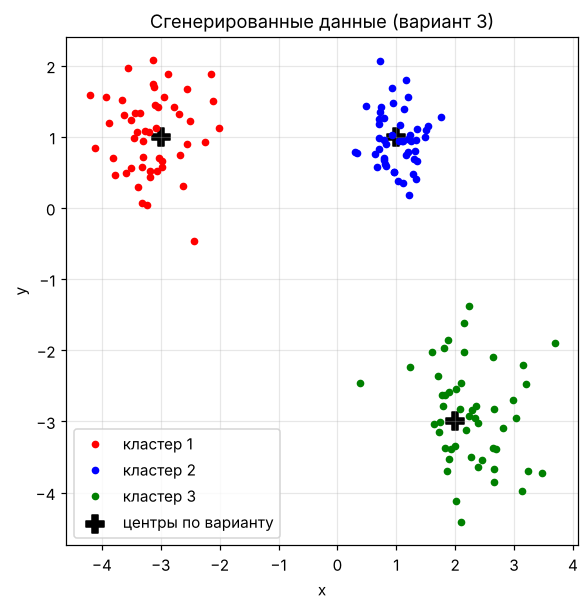

In [3]:
plt.figure(figsize=(6, 6))
for j, style in enumerate(["ro", "bo", "go"]):
    plt.plot(X[y_true == j, 0], X[y_true == j, 1], style, markersize=4, label=f"кластер {j + 1}")
plt.scatter(centers_true[:, 0], centers_true[:, 1], marker="P", s=150, c="black", label="центры по варианту")
plt.title("Сгенерированные данные (вариант 3)")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Задание 2. Реализация метода k-means вручную (cdist)

In [4]:
def wcss(X, labels, centroids):
    """Сумма квадратов расстояний от точек до центроидов своих кластеров."""
    return float(((X - centroids[labels]) ** 2).sum())


def kmeans_manual(X, M, n_iter=3, seed=SEED):
    """Метод k-средних: случайные центроиды -> назначение -> пересчёт центров."""
    np.random.seed(seed)
    centroids = np.random.normal(loc=0.0, scale=1.0, size=(M, 2)).reshape((M, 2))
    cent_history = [centroids.copy()]       # история центроидов (шаг 0 - начальные)
    labels_history = [None]
    for _ in range(n_iter):
        distances = cdist(X, centroids)     # расстояния от всех точек до центроидов
        labels = distances.argmin(axis=1)   # индекс ближайшего центроида
        centroids = centroids.copy()
        for j in range(M):
            if np.any(labels == j):         # пустой кластер оставляем на месте
                centroids[j, :] = X[labels == j].mean(axis=0)
        cent_history.append(centroids.copy())
        labels_history.append(labels)
    return centroids, labels, cent_history, labels_history

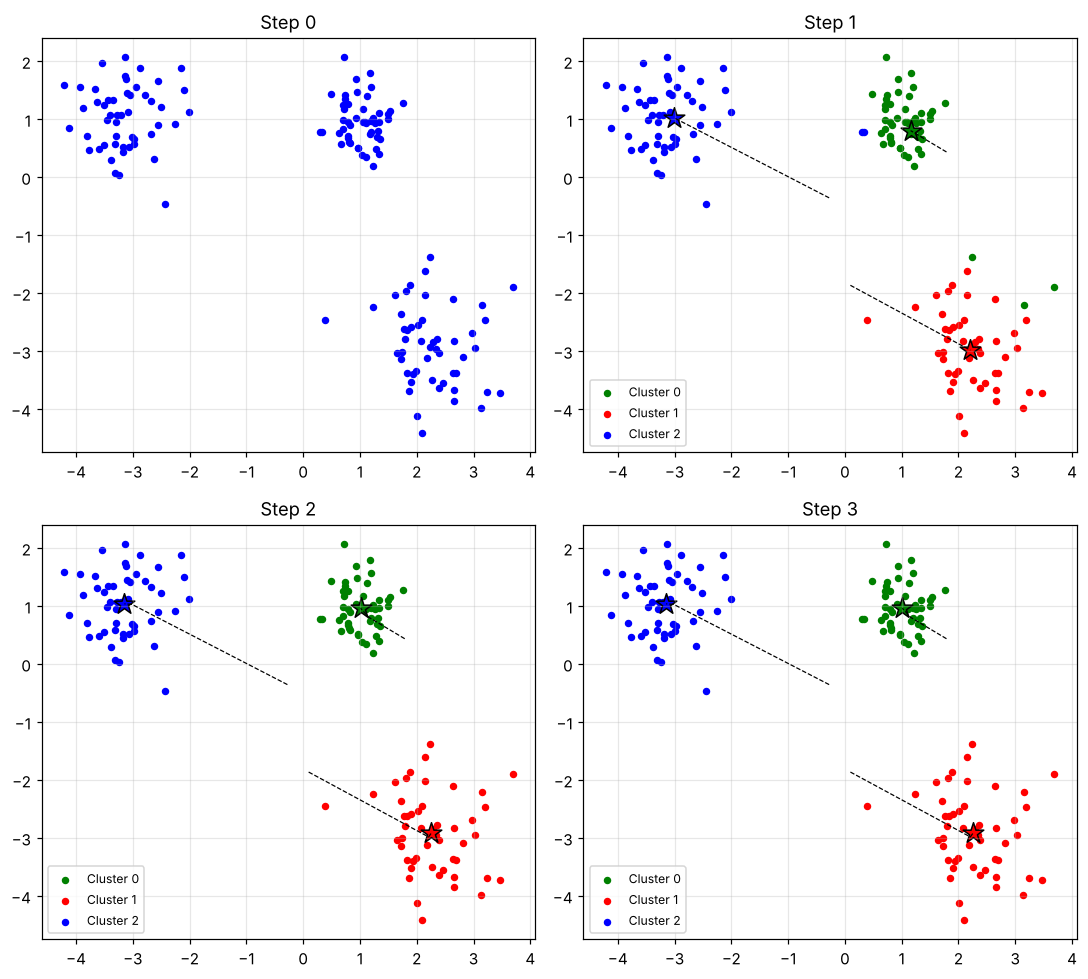

In [5]:
M = 3
N_ITER = 3
centroids, labels, cent_history, labels_history = kmeans_manual(X, M, n_iter=N_ITER)

colors = ["g", "r", "b", "c", "m"]
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for step, ax in enumerate(axes.ravel()):
    if step == 0:
        ax.scatter(X[:, 0], X[:, 1], marker="o", c="b", s=15)
    else:
        for j in range(M):
            pts = X[labels_history[step] == j]
            ax.scatter(pts[:, 0], pts[:, 1], marker="o", c=colors[j], s=15, label=f"Cluster {j}")
            ax.scatter(*cent_history[step][j], marker="*", s=200, c=colors[j], edgecolors="black")
        ax.legend(loc="lower left", fontsize=8)
    # траектории центроидов
    for j in range(M):
        path = np.array([h[j] for h in cent_history[: step + 1]])
        ax.plot(path[:, 0], path[:, 1], "k--", linewidth=0.8)
    ax.set_title(f"Step {step}")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Сравнение найденных центроидов с центрами по варианту и с эталоном sklearn
d = cdist(centroids, centers_true)
match = d.argmin(axis=1)
res = pd.DataFrame({
    "центроид": range(M),
    "x": centroids[:, 0], "y": centroids[:, 1],
    "ближайший истинный центр": [tuple(centers_true[k]) for k in match],
    "расстояние": d.min(axis=1),
})
display(res)

ref = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=SEED).fit(X)
print("WCSS (ручная реализация, 3 итерации):", round(wcss(X, labels, centroids), 3))
print("WCSS (sklearn KMeans):               ", round(ref.inertia_, 3))
print("Смещение центроидов на последней итерации:", float(np.abs(cent_history[-1] - cent_history[-2]).max()))
print("ARI относительно истинных меток:", round(adjusted_rand_score(y_true, labels), 3))

,центроид,x,y,ближайший истинный центр,расстояние
0,0,1.012,0.962,"(1, 1)",0.040
1,1,2.258,-2.914,"(2, -3)",0.272
2,2,-3.147,1.038,"(-3, 1)",0.152


WCSS (ручная реализация, 3 итерации): 80.135
WCSS (sklearn KMeans):                80.135
Смещение центроидов на последней итерации: 0.0
ARI относительно истинных меток: 1.0


#### Неправильное число кластеров (M = 2 и M = 5)

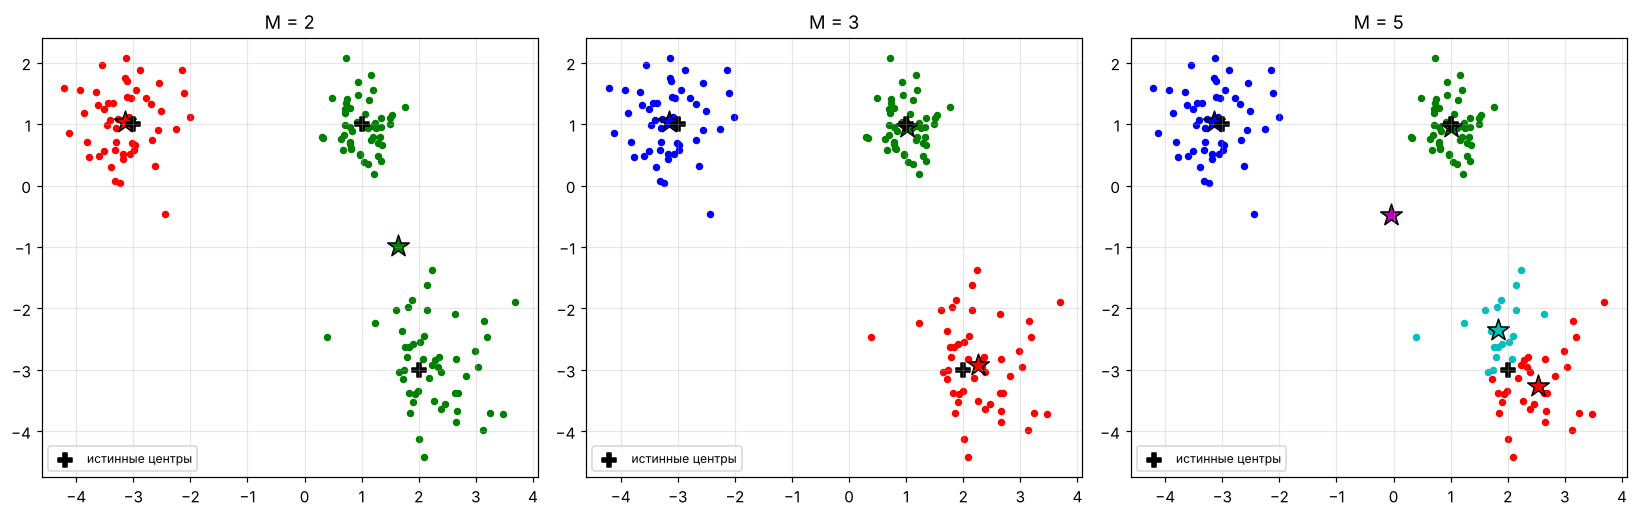

,M,WCSS,silhouette,ARI
0,2,494.494,0.620,0.568
1,3,80.135,0.774,1.000
2,5,64.404,0.643,0.876


In [7]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, M_try in zip(axes, [2, 3, 5]):
    c_m, l_m, _, _ = kmeans_manual(X, M_try, n_iter=10)
    for j in range(M_try):
        ax.scatter(X[l_m == j, 0], X[l_m == j, 1], c=colors[j], s=15)
        ax.scatter(*c_m[j], marker="*", s=220, c=colors[j], edgecolors="black")
    ax.scatter(centers_true[:, 0], centers_true[:, 1], marker="P", s=90, c="black", label="истинные центры")
    ax.set_title(f"M = {M_try}")
    ax.grid(alpha=0.3); ax.legend(loc="lower left", fontsize=8)
    rows.append({"M": M_try, "WCSS": wcss(X, l_m, c_m),
                 "silhouette": silhouette_score(X, l_m),
                 "ARI": adjusted_rand_score(y_true, l_m)})
plt.tight_layout()
plt.show()
display(pd.DataFrame(rows))

### Задание 3. k-means (sklearn): правило локтя и коэффициент силуэта

In [8]:
K_range = range(1, 11)
inertia = []
for k in K_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED)
    km.fit(X)
    inertia.append(km.inertia_)

K_range_sil = range(2, 11)
silhouette_scores = []
for k in K_range_sil:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED)
    silhouette_scores.append(silhouette_score(X, km.fit_predict(X)))

# локоть: точка, наиболее удалённая от прямой, соединяющей первую и последнюю точки WCSS(k)
kk = np.array(list(K_range), dtype=float)
ii = np.array(inertia)
kn, inn = (kk - kk.min()) / (kk.max() - kk.min()), (ii - ii.min()) / (ii.max() - ii.min())
dist_line = np.abs((inn[-1] - inn[0]) * kn - (kn[-1] - kn[0]) * inn + kn[-1] * inn[0] - inn[-1] * kn[0])
elbow_k = int(kk[dist_line.argmax()])
best_k = list(K_range_sil)[int(np.argmax(silhouette_scores))]

table_k = pd.DataFrame({"k": list(K_range), "WCSS": inertia,
                        "silhouette": [np.nan] + silhouette_scores})
display(table_k)
print("Излом (локоть) по WCSS: k =", elbow_k)
print("Лучшее k по силуэту:    k =", best_k, "(s = %.3f)" % max(silhouette_scores))

,k,WCSS,silhouette
0,1,1391.921,NaN
1,2,494.494,0.620
2,3,80.135,0.774
3,4,64.338,0.643
4,5,53.853,0.506
5,6,47.573,0.507
6,7,40.299,0.511
7,8,35.779,0.352
8,9,31.555,0.346
9,10,28.798,0.340


Излом (локоть) по WCSS: k = 3
Лучшее k по силуэту:    k = 3 (s = 0.774)


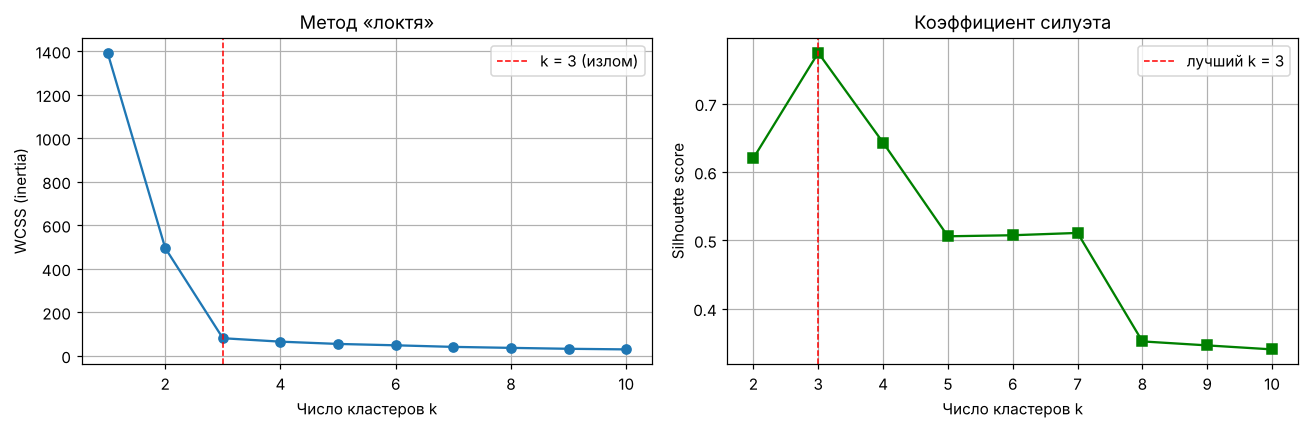

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(K_range), inertia, "o-")
ax[0].axvline(elbow_k, color="red", linestyle="--", linewidth=1, label=f"k = {elbow_k} (излом)")
ax[0].set(title="Метод «локтя»", xlabel="Число кластеров k", ylabel="WCSS (inertia)")
ax[1].plot(list(K_range_sil), silhouette_scores, "s-", color="green")
ax[1].axvline(best_k, color="red", linestyle="--", linewidth=1, label=f"лучший k = {best_k}")
ax[1].set(title="Коэффициент силуэта", xlabel="Число кластеров k", ylabel="Silhouette score")
for a in ax:
    a.grid(True); a.legend()
plt.tight_layout()
plt.show()

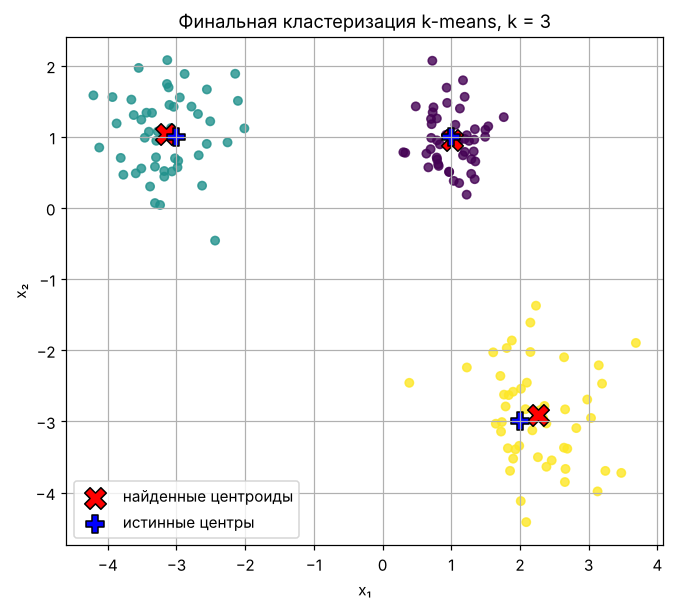

Найденные центроиды:
 [[ 1.012  0.962]
 [-3.147  1.038]
 [ 2.258 -2.914]]
Расстояние до ближайшего истинного центра: [0.04  0.152 0.272]
ARI относительно истинных меток: 1.0


In [10]:
km_final = KMeans(n_clusters=best_k, init="k-means++", n_init=10, random_state=SEED)
labels_final = km_final.fit_predict(X)
centers_final = km_final.cluster_centers_

plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels_final, cmap="viridis", s=30, alpha=0.8)
plt.scatter(centers_final[:, 0], centers_final[:, 1], c="red", marker="X", s=200,
            edgecolor="black", label="найденные центроиды")
plt.scatter(centers_true[:, 0], centers_true[:, 1], c="blue", marker="P", s=150,
            edgecolor="black", label="истинные центры")
plt.title(f"Финальная кластеризация k-means, k = {best_k}")
plt.xlabel("x₁"); plt.ylabel("x₂")
plt.legend(); plt.grid(True)
plt.show()

dd = cdist(centers_final, centers_true)
print("Найденные центроиды:\n", centers_final.round(3))
print("Расстояние до ближайшего истинного центра:", dd.min(axis=1).round(3))
print("ARI относительно истинных меток:", round(adjusted_rand_score(y_true, labels_final), 3))

## Часть 2. Иерархическая кластеризация

### Задание 4. Агломеративная кластеризация (метод Уорда) и дендрограмма

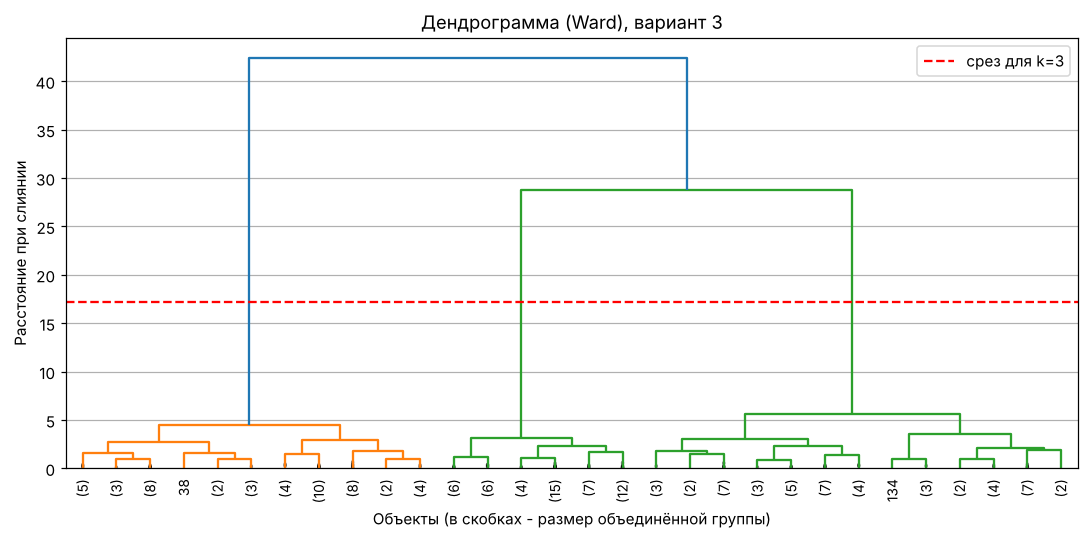

Высоты трёх последних слияний: [ 5.62 28.79 42.37]
Порог отсечения: 17.2


In [11]:
Z = linkage(X, method="ward")

# порог отсечения для k = 3: между слиянием 3 -> 2 кластера и слиянием 4 -> 3 кластера
cut = (Z[-3, 2] + Z[-2, 2]) / 2

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_contracted=True, leaf_rotation=90, leaf_font_size=9)
plt.title("Дендрограмма (Ward), вариант 3")
plt.axhline(y=cut, color="red", linestyle="--", label="срез для k=3")
plt.xlabel("Объекты (в скобках - размер объединённой группы)")
plt.ylabel("Расстояние при слиянии")
plt.legend(); plt.grid(True, axis="y")
plt.tight_layout()
plt.show()

print("Высоты трёх последних слияний:", Z[-3:, 2].round(2))
print("Порог отсечения:", round(cut, 2))

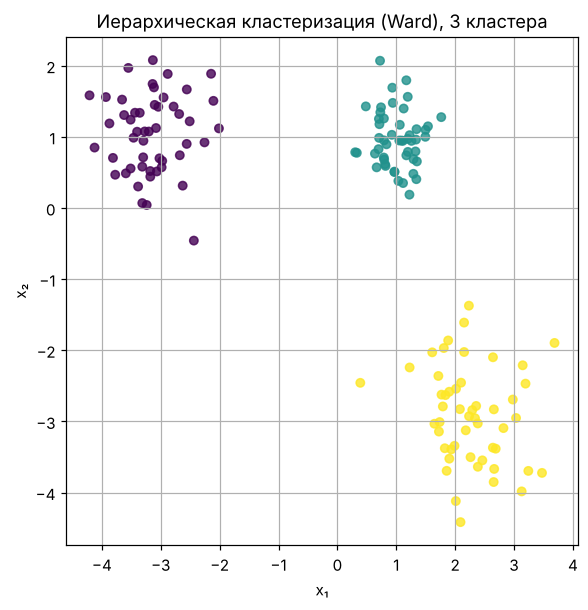

Размеры кластеров: [50 50 50]
ARI (иерархическая vs истинные метки): 1.0
ARI (иерархическая vs k-means):        1.0


,linkage,размеры кластеров,ARI
0,ward,"[50, 50, 50]",1.0
1,complete,"[50, 50, 50]",1.0
2,average,"[50, 50, 50]",1.0
3,single,"[50, 50, 50]",1.0


In [12]:
labels_h = fcluster(Z, t=3, criterion="maxclust") - 1

plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels_h, cmap="viridis", s=30, alpha=0.8)
plt.title("Иерархическая кластеризация (Ward), 3 кластера")
plt.xlabel("x₁"); plt.ylabel("x₂"); plt.grid(True)
plt.show()

print("Размеры кластеров:", np.bincount(labels_h))
print("ARI (иерархическая vs истинные метки):", round(adjusted_rand_score(y_true, labels_h), 3))
print("ARI (иерархическая vs k-means):       ", round(adjusted_rand_score(labels_final, labels_h), 3))

# сравнение способов объединения кластеров
rows = []
for method in ["ward", "complete", "average", "single"]:
    lab = fcluster(linkage(X, method=method), t=3, criterion="maxclust") - 1
    rows.append({"linkage": method, "размеры кластеров": np.bincount(lab).tolist(),
                 "ARI": adjusted_rand_score(y_true, lab)})
display(pd.DataFrame(rows))

## Часть 3. Нейронная сеть Кохонена

### Задание 5. Слой Кохонена: K = 6, N = 5, σ = 0,06, новый вектор (0,3; 0,7)

In [13]:
K_CL, N_PTS, SIGMA = 6, 5, 0.06     # параметры варианта 3
A, B = 0.3, 0.7                     # новый вектор p = (A; B)

def nngen(centers, points, std, seed=SEED):
    """K кластеров по `points` точек из N(mu_i, std^2)."""
    rng = np.random.default_rng(seed)
    parts = [rng.normal(c, std, (points, 2)) for c in centers]
    return np.vstack(parts), np.repeat(np.arange(len(centers)), points)

# 6 центров кластеров в единичном квадрате (выбраны самостоятельно)
centers_k = np.array([[0.2, 0.3], [0.7, 0.2], [0.5, 0.8],
                      [0.2, 0.8], [0.85, 0.65], [0.5, 0.5]])
P, y_k = nngen(centers_k, points=N_PTS, std=SIGMA)
print("Размер выборки P:", P.shape)

Размер выборки P: (30, 2)


In [14]:
class KohonenLayer:
    def __init__(self, n_neurons=5, lr=0.1, epochs=50, seed=SEED):
        self.n = n_neurons
        self.lr = lr
        self.epochs = epochs
        self.rng = np.random.default_rng(seed)

    def init_weights(self, X):
        # инициализация весов в диапазоне данных
        lo, hi = X.min(axis=0), X.max(axis=0)
        self.W = self.rng.uniform(lo, hi, (self.n, X.shape[1]))

    def train(self, X):
        for epoch in range(self.epochs):
            lr = self.lr * (1 - epoch / self.epochs)       # затухание скорости обучения
            for x in X:
                d = np.linalg.norm(self.W - x, axis=1)
                j = d.argmin()                              # нейрон-победитель
                self.W[j] += lr * (x - self.W[j])           # w_j <- w_j + eta (x - w_j)
        return self

    def winner(self, x):
        d = np.linalg.norm(self.W - x, axis=1)
        return int(d.argmin())

    def win_counts(self, X):
        return np.bincount([self.winner(x) for x in X], minlength=self.n)

In [15]:
net = KohonenLayer(n_neurons=K_CL, lr=0.1, epochs=50)
net.init_weights(P)
W0 = net.W.copy()                      # веса до обучения
net.train(P)
w = net.W

print("Веса нейронов до обучения:\n", W0.round(3))
print("\nВеса нейронов после обучения (центры кластеров):\n", w.round(3))
print("\nЧисло точек, закреплённых за каждым нейроном:", net.win_counts(P))

dc = cdist(centers_k, w)
cmp_table = pd.DataFrame({
    "истинный центр": [tuple(c) for c in centers_k],
    "ближайший нейрон": dc.argmin(axis=1),
    "вес нейрона": [tuple(w[j].round(3)) for j in dc.argmin(axis=1)],
    "ошибка": dc.min(axis=1),
})
display(cmp_table)

Веса нейронов до обучения:
 [[0.108 0.323]
 [0.755 0.581]
 [0.115 0.47 ]
 [0.463 0.266]
 [0.694 0.231]
 [0.384 0.532]]

Веса нейронов после обучения (центры кластеров):
 [[0.187 0.301]
 [0.868 0.668]
 [0.154 0.803]
 [0.513 0.462]
 [0.705 0.178]
 [0.525 0.828]]

Число точек, закреплённых за каждым нейроном: [5 5 5 5 5 5]


,истинный центр,ближайший нейрон,вес нейрона,ошибка
0,"(0.2, 0.3)",0,"(0.187, 0.301)",0.013
1,"(0.7, 0.2)",4,"(0.705, 0.178)",0.022
2,"(0.5, 0.8)",5,"(0.525, 0.828)",0.037
3,"(0.2, 0.8)",2,"(0.154, 0.803)",0.046
4,"(0.85, 0.65)",1,"(0.868, 0.668)",0.025
5,"(0.5, 0.5)",3,"(0.513, 0.462)",0.040


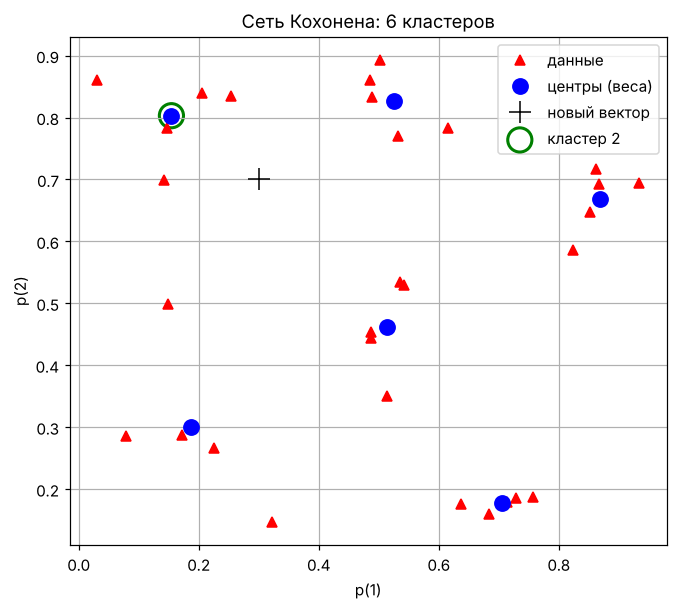

Победивший нейрон (кластер): 2
Центр-победитель: [0.154 0.803]
Расстояние от p до победителя: 0.178

Расстояния от p до всех нейронов:
 [0.415 0.569 0.178 0.319 0.66  0.259]
Ближайший истинный центр к p: [0.2 0.8]


In [16]:
p_new = np.array([A, B])
j = net.winner(p_new)

plt.figure(figsize=(7, 6))
plt.plot(P[:, 0], P[:, 1], "^r", label="данные")
plt.plot(w[:, 0], w[:, 1], "ob", markersize=10, label="центры (веса)")
plt.plot(A, B, "+k", markersize=14, label="новый вектор")
plt.scatter(w[j, 0], w[j, 1], s=250, facecolors="none", edgecolors="green", linewidths=2,
            label=f"кластер {j}")
plt.xlabel("p(1)"); plt.ylabel("p(2)")
plt.legend(); plt.grid(True)
plt.title(f"Сеть Кохонена: {K_CL} кластеров")
plt.show()

print("Победивший нейрон (кластер):", j)
print("Центр-победитель:", w[j].round(3))
print("Расстояние от p до победителя:", round(float(np.linalg.norm(w[j] - p_new)), 3))
print("\nРасстояния от p до всех нейронов:\n", np.linalg.norm(w - p_new, axis=1).round(3))
print("Ближайший истинный центр к p:", centers_k[np.linalg.norm(centers_k - p_new, axis=1).argmin()])

#### Влияние числа нейронов и инициализации весов

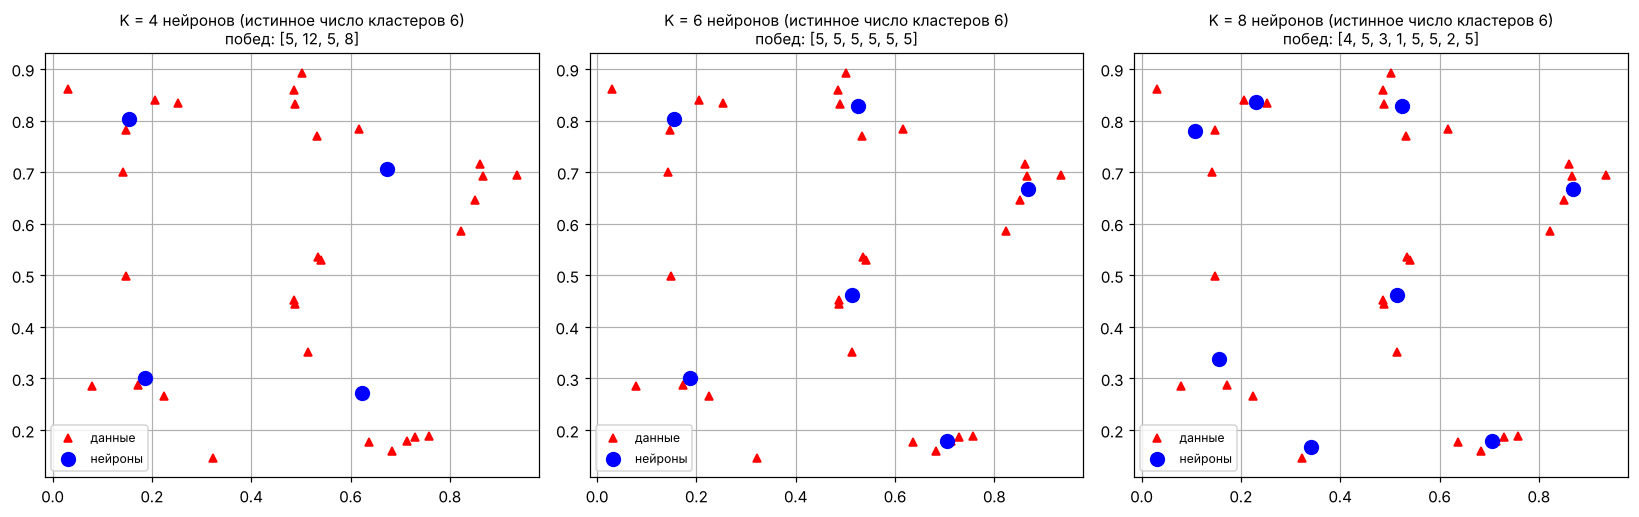

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, K_try in zip(axes, [4, 6, 8]):
    nt = KohonenLayer(n_neurons=K_try, lr=0.1, epochs=50)
    nt.init_weights(P); nt.train(P)
    ax.plot(P[:, 0], P[:, 1], "^r", markersize=5, label="данные")
    ax.plot(nt.W[:, 0], nt.W[:, 1], "ob", markersize=9, label="нейроны")
    ax.set_title(f"K = {K_try} нейронов (истинное число кластеров 6)\nпобед: {nt.win_counts(P).tolist()}", fontsize=10)
    ax.grid(True); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

In [18]:
rows = []
for s in range(3, 13):
    nt = KohonenLayer(n_neurons=K_CL, lr=0.1, epochs=50, seed=s)
    nt.init_weights(P); nt.train(P)
    err = cdist(centers_k, nt.W).min(axis=1)
    rows.append({"seed": s, "мёртвых нейронов": int((nt.win_counts(P) == 0).sum()),
                 "макс. ошибка центра": err.max(),
                 "все 6 центров найдены (ошибка < 0,1)": bool(err.max() < 0.1)})
seed_table = pd.DataFrame(rows)
display(seed_table)
print("Успешных запусков:", int(seed_table.iloc[:, 3].sum()), "из", len(seed_table))

,seed,мёртвых нейронов,макс. ошибка центра,"все 6 центров найдены (ошибка < 0,1)"
0,3,0,0.046,True
1,4,1,0.309,False
2,5,0,0.212,False
3,6,1,0.199,False
4,7,0,0.246,False
5,8,0,0.250,False
6,9,0,0.046,True
7,10,1,0.199,False
8,11,0,0.187,False
9,12,0,0.046,True


Успешных запусков: 3 из 10


## Выводы
Результаты и выводы по заданиям приведены в отчёте (docx). Кратко: k-means с правильным k = 3 восстанавливает исходные центры; при M = 2 и M = 5 кластеры объединяются или дробятся; правило локтя и коэффициент силуэта согласованно указывают k = 3; иерархическая кластеризация (Ward) даёт то же разбиение; слой Кохонена с K = 6 нейронами находит 6 центров, но результат зависит от инициализации весов.